In [2]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as pt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler,MinMaxScaler,PolynomialFeatures,MaxAbsScaler
from sklearn.linear_model import Lasso,Ridge,LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.model_selection import train_test_split

In [4]:
df=pd.read_csv('SELmart.csv',parse_dates=['Month'])
df.head()

,Month,Revenue
0,2022-01-01,266.0
1,2022-02-01,145.9
2,2022-03-01,183.1
3,2022-04-01,119.3
4,2022-05-01,180.3


In [5]:
df.shape

(36, 2)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Month    36 non-null     object 
 1   Revenue  36 non-null     float64
dtypes: float64(1), object(1)
memory usage: 708.0+ bytes


In [10]:
df.describe()

,Revenue
count,36.000000
mean,312.600000
std,148.937164
min,119.300000
25%,192.450000
50%,280.150000
75%,411.100000
max,682.000000


In [11]:
df.dtypes

Month       object
Revenue    float64
dtype: object

In [7]:
df['SMA']=df['Revenue'].rolling(window=20).mean()

In [26]:
last_month=df['Month'].iloc[-1]
last_sma=df['SMA'].iloc[-1]
future=pd.date_range(start=last_month,periods=25, freq='M')[1:]
forecast=pd.DataFrame({'Forecast':[last_sma]*24},index=future)

In [27]:
print(forecast)

            Forecast
2025-01-31   403.445
2025-02-28   403.445
2025-03-31   403.445
2025-04-30   403.445
2025-05-31   403.445
2025-06-30   403.445
2025-07-31   403.445
2025-08-31   403.445
2025-09-30   403.445
2025-10-31   403.445
2025-11-30   403.445
2025-12-31   403.445
2026-01-31   403.445
2026-02-28   403.445
2026-03-31   403.445
2026-04-30   403.445
2026-05-31   403.445
2026-06-30   403.445
2026-07-31   403.445
2026-08-31   403.445
2026-09-30   403.445
2026-10-31   403.445
2026-11-30   403.445
2026-12-31   403.445


In [29]:
print(last_sma)

403.445


In [75]:
df

,Month,Revenue,SMA
0,2022-01-01,266.0,NaN
1,2022-02-01,145.9,NaN
2,2022-03-01,183.1,NaN
3,2022-04-01,119.3,NaN
4,2022-05-01,180.3,NaN
5,2022-06-01,168.5,NaN
6,2022-07-01,231.8,NaN
7,2022-08-01,224.5,NaN
8,2022-09-01,192.8,NaN
9,2022-10-01,122.9,NaN


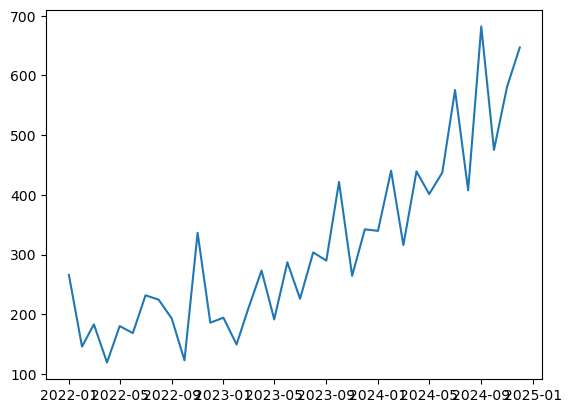

In [76]:
pt.plot(df['Month'],df['Revenue'])

# Simple Exponential Smoothing

# when you select your alpha

In [77]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

In [78]:
 
model=SimpleExpSmoothing(df['Revenue']).fit(smoothing_level=.3,optimized=False)
model.summary()

Dep. Variable:,Revenue,No. Observations:,36
Model:,SimpleExpSmoothing,SSE,260921.099
Optimized:,False,AIC,323.984
Trend:,None,BIC,327.151
Seasonal:,None,AICC,325.275
Seasonal Periods:,None,Date:,"Thu, 16 Jul 2026"
Box-Cox:,False,Time:,05:08:17
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.3000000,alpha,False
initial_level,266.00000,l.0,False


# when you want to find forecasted values

In [79]:
forecast=model.forecast(1)
forecast

36    561.389999
dtype: float64

# when python selects an optimized alpha

In [81]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing


In [105]:
model=SimpleExpSmoothing(df['Revenue']).fit()
model.summary()

Dep. Variable:,Revenue,No. Observations:,36
Model:,SimpleExpSmoothing,SSE,247635.134
Optimized:,True,AIC,322.103
Trend:,None,BIC,325.270
Seasonal:,None,AICC,323.393
Seasonal Periods:,None,Date:,"Thu, 16 Jul 2026"
Box-Cox:,False,Time:,05:18:43
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.4168589,alpha,True
initial_level,266.00000,l.0,False


# Double Exponential Smoothing
# WHEN YOU DEFINE YOUR SMOOTHING LEVEL AND TREND

In [106]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [107]:
model=ExponentialSmoothing(df['Revenue'],trend='add',seasonal=None).fit(smoothing_level=.3,smoothing_trend=.4,optimized=False)

In [108]:
model.summary()

Dep. Variable:,Revenue,No. Observations:,36
Model:,ExponentialSmoothing,SSE,204204.369
Optimized:,False,AIC,319.161
Trend:,Additive,BIC,325.495
Seasonal:,None,AICC,322.057
Seasonal Periods:,None,Date:,"Thu, 16 Jul 2026"
Box-Cox:,False,Time:,05:18:48
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.3000000,alpha,False
smoothing_trend,0.4000000,beta,False


In [109]:
model.forecast(6)

36    647.676398
37    677.083903
38    706.491408
39    735.898913
40    765.306418
41    794.713923
dtype: float64

# WHEN PYTHON SELECTS AN ALPHA AND BETA

In [110]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [111]:
model=ExponentialSmoothing(df['Revenue'],trend='add').fit()

In [112]:
model.summary()

Dep. Variable:,Revenue,No. Observations:,36
Model:,ExponentialSmoothing,SSE,182530.680
Optimized:,True,AIC,315.122
Trend:,Additive,BIC,321.456
Seasonal:,None,AICC,318.018
Seasonal Periods:,None,Date:,"Thu, 16 Jul 2026"
Box-Cox:,False,Time:,05:18:51
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.2061725,alpha,True
smoothing_trend,0.2061725,beta,True


In [113]:
model.forecast(6)

36    627.860834
37    653.385805
38    678.910777
39    704.435749
40    729.960720
41    755.485692
dtype: float64

# Triple Exponential Smoothing
# when you select your smoothing level,trends and seasonal

In [114]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [115]:
model=ExponentialSmoothing(df['Revenue'],trend='add',seasonal='add',seasonal_periods=7).fit(smoothing_level=.5,smoothing_trend=.5,smoothing_seasonal=.6,optimized=False)

In [116]:
model.summary()

Dep. Variable:,Revenue,No. Observations:,36
Model:,ExponentialSmoothing,SSE,346852.461
Optimized:,False,AIC,352.233
Trend:,Additive,BIC,369.652
Seasonal:,Additive,AICC,368.778
Seasonal Periods:,7,Date:,"Thu, 16 Jul 2026"
Box-Cox:,False,Time:,05:18:52
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.5000000,alpha,False
smoothing_trend,0.5000000,beta,False


In [117]:
model.forecast(6)

36    682.863739
37    794.234548
38    670.791912
39    927.897775
40    712.019067
41    838.501160
dtype: float64

# When python selects the alpha,beta and Gamma

In [118]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [119]:
model=ExponentialSmoothing(df['Revenue'],trend='add',seasonal='add',seasonal_periods=7).fit()

In [120]:
model.summary()

Dep. Variable:,Revenue,No. Observations:,36
Model:,ExponentialSmoothing,SSE,156424.356
Optimized:,True,AIC,323.565
Trend:,Additive,BIC,340.984
Seasonal:,Additive,AICC,340.111
Seasonal Periods:,7,Date:,"Thu, 16 Jul 2026"
Box-Cox:,False,Time:,05:18:53
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.2096567,alpha,True
smoothing_trend,0.2096567,beta,True


In [121]:
model.forecast(6)

36    605.957474
37    640.002501
38    668.290012
39    725.157465
40    685.935461
41    743.484351
dtype: float64

# AU Revior=========Goodbye